# 06 — Advanced EDA: why do the models plateau?

Every architecture, size and optimiser we tried hits the same wall: the validation loss stalls
around 0.74 (standardised MSE), real labels are memorised barely faster than shuffled ones, the
time constants are almost not learned, unheated tests give no HLC, and the split
`HLC_mit` / `HLC_ext` is hard. This notebook looks for the causes **in the data alone**, without
any trained model.

| # | Question | Section |
|---|---|---|
| 1 | What inputs does the dataset contain? | 1 |
| 2 | Is the measurement resolution a limit? | 2 |
| 3 | How much of a curve does the building explain, and how much the hidden initial state? | 3 |
| 4 | How much information about each target does a test contain, and which tests are best? | 4 |
| 5 | Would a longer test help? | 5 |
| 6 | Can two different buildings give the same curve? | 6 |
| 7 | What does the curve actually measure (physics)? | 7 |

**Key fact found while preparing this notebook:** the PRBS generator always used the same seed,
so the 1M simulations contain only a few thousand distinct heating sequences. Many simulations
received **exactly the same input**. Within such a group, the curves differ only because of the
building and the hidden initial state: a controlled experiment, used throughout.

Helpers: `ipe_prediction.eda.identifiability`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)

from ipe_prediction.eda import identifiability as I
from ipe_prediction.eda import plotting as P
from ipe_prediction.training.config import DataConfig
from ipe_prediction.training.dataset import prepare_data

P.set_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
torch.manual_seed(0)

tensors, split = prepare_data(DataConfig())
dT, U = tensors.delta_t, tensors.heater_on
Y = I.target_view(tensors.targets)  # HLC, HLC_mit, HLC_ext (W/K), log taus, log C_n
names = list(I.VIEW_NAMES)
hours = np.arange(dT.shape[1]) / 60
STEP = 5  # curves downsampled to 5 min (96 points) for the regressions


def curves(idx):
    return dT[idx][:, ::STEP]

## 1. The inputs: a few thousand distinct heating sequences

In [2]:
group, size = I.input_groups(U)
G, N = len(size), len(group)
rep = torch.empty(G, dtype=torch.long)
rep[group] = torch.arange(N)  # one simulation per group
u_rep = U[rep].float()
groups = pd.DataFrame({
    "size": size.numpy(),
    "duty cycle": u_rep.mean(1).numpy(),
    "switches": u_rep.diff(dim=1).abs().sum(1).numpy(),
})
groups["mean step (h)"] = 8 / (groups["switches"] + 1)
groups["regime"] = np.select([groups["duty cycle"] == 0, groups["duty cycle"] == 1], ["never on", "always on"], "PRBS")
print(f"{N:,} simulations, {G:,} distinct heating sequences; prbs_seed values: "
      f"{torch.unique(tensors.excitation_column('prbs_seed')).tolist()}")
share = {f">= {k}": float(size[group].ge(k).float().mean()) for k in (2, 10, 100, 1000, 5000)}
display(pd.Series(share, name="share of simulations in a group of size").round(3).to_frame().T)
display(groups.head(10))

in_train = torch.zeros(G, dtype=torch.bool)
in_train[group[split["train"]]] = True
print(f"validation simulations whose exact input also appears in training: {in_train[group[split['val']]].float().mean():.2%}")

1,000,000 simulations, 2,798 distinct heating sequences; prbs_seed values: [42.0]


,>= 2,>= 10,>= 100,>= 1000,>= 5000
share of simulations in a group of size,1.0,0.998,0.932,0.65,0.216


,size,duty cycle,switches,mean step (h),regime
0,84164,0.000,0.0,8.0,never on
1,14670,0.656,1.0,4.0,PRBS
2,14600,0.654,1.0,4.0,PRBS
3,8850,0.738,1.0,4.0,PRBS
4,8818,0.621,1.0,4.0,PRBS
5,8759,0.581,1.0,4.0,PRBS
6,8751,0.579,1.0,4.0,PRBS
7,8711,1.000,0.0,8.0,always on
8,5916,0.781,1.0,4.0,PRBS
9,5903,0.598,1.0,4.0,PRBS


validation simulations whose exact input also appears in training: 99.99%


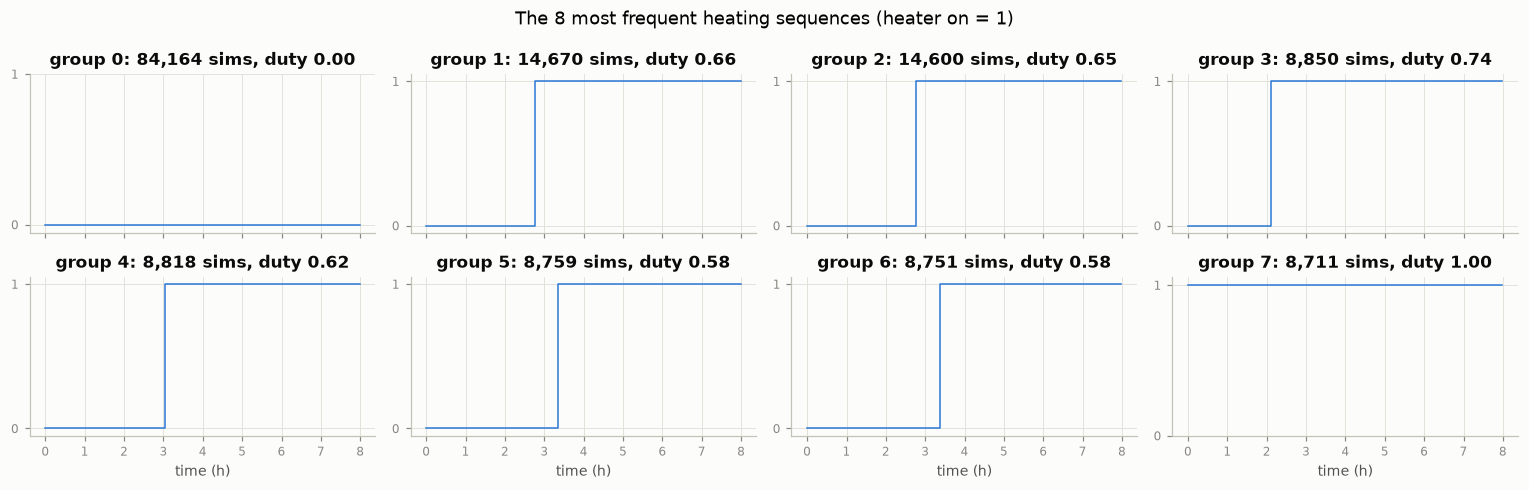

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(14, 4.5), sharex=True)
for ax, g in zip(axes.flat, range(8)):
    ax.step(hours, u_rep[g].numpy(), where="post", lw=1)
    row = groups.loc[g]
    ax.set(title=f"group {g}: {row['size']:,} sims, duty {row['duty cycle']:.2f}", yticks=[0, 1])
for ax in axes[1]:
    ax.set_xlabel("time (h)")
fig.suptitle("The 8 most frequent heating sequences (heater on = 1)")
fig.tight_layout()

**Reading.** One seed for the PRBS generator means the sequence is fully determined by the
switching settings, so whole families of simulations share it. Every validation and test
input also occurs in training: the scores we measured are scores **on known protocols**. How
well a model generalises to a **new** heating sequence is not measured by the current split.
Within a group, the input is identical, so we can study building vs hidden state directly.

## 2. Measurement resolution

The temperatures are rounded to 0.01 °C (as in the assessment's loading code). Per-minute
increments are compared with that quantum.

In [4]:
sample = torch.randperm(N)[:100_000]
inc = dT[sample].diff(dim=1)
reg = groups["regime"].to_numpy()[group[sample].numpy()]
rows = {}
for r in ["never on", "always on", "PRBS"]:
    m = torch.from_numpy(reg == r)
    d = inc[m]
    rows[r] = {"share of exactly-zero 1-min increments": float((d == 0).float().mean()),
               "share with |increment| <= 0.01 °C": float((d.abs() <= 0.0101).float().mean()),
               "median |increment| (°C/min)": float(d.abs().median()),
               "mean |slope| over 8 h (°C/min)": float((dT[sample][m][:, -1] - dT[sample][m][:, 0]).abs().mean() / 479)}
display(pd.DataFrame(rows).T)

,share of exactly-zero 1-min increments,share with |increment| <= 0.01 °C,median |increment| (°C/min),mean |slope| over 8 h (°C/min)
never on,0.718,0.994,0.00,0.002
always on,0.039,0.452,0.02,0.032
PRBS,0.161,0.425,0.02,0.018


**Reading.** When the heater is off, the temperature moves by less than one quantum per minute:
most 1-min increments are 0 or ±0.01 °C, so the instantaneous slope is mostly rounding noise.
Information is in slopes over tens of minutes, not in 1-minute derivatives. This does not
explain the plateau (models average over many steps), but rules out derivative features at full
resolution.

## 3. Building vs hidden initial state: how much of a curve does the building explain?

Within one input group, the curve of each simulation is predicted from the curves of the 20
simulations with the **most similar targets** (leave-one-out). The share of the variance of the
curve explained at each time is the part due to the building; the rest is due to the hidden
initial state (the targets are known exactly here, the input is identical).

,mean R² over 8 h,R² at 1 h,R² at 8 h
never on,0.199,0.019,0.231
PRBS (group 1),0.630,0.012,0.980
always on,0.936,0.874,0.974


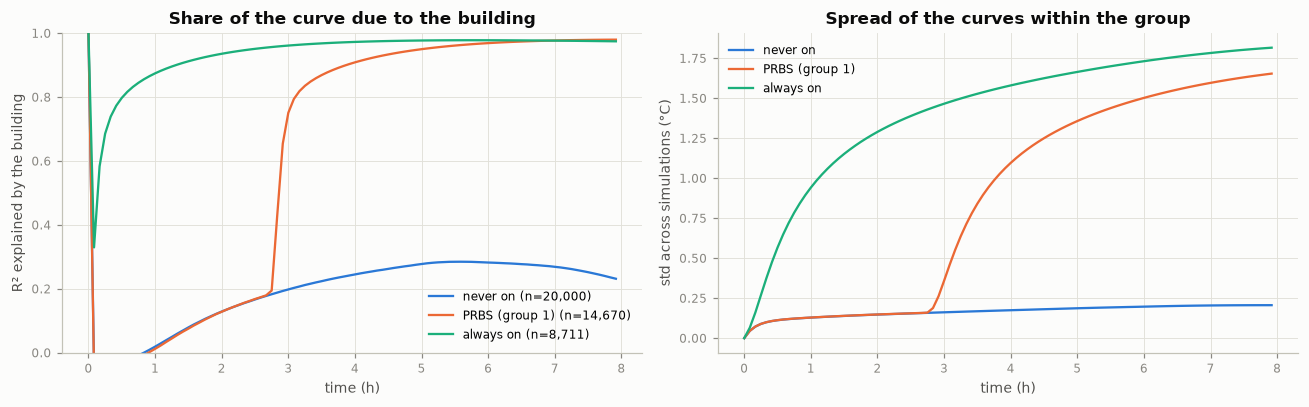

In [5]:
first_prbs = int(groups.index[groups["regime"] == "PRBS"][0])
always = int(groups.index[groups["regime"] == "always on"][0])
never = int(groups.index[groups["regime"] == "never on"][0])
study = {"never on": never, f"PRBS (group {first_prbs})": first_prbs, "always on": always}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
forward = {}
for label, g in study.items():
    idx = (group == g).nonzero().flatten()
    idx = idx[torch.randperm(len(idx))[:20_000]]
    r2_t = I.knn_forward_r2(Y[idx], dT[idx][:, ::STEP])
    forward[label] = r2_t
    axes[0].plot(hours[::STEP], r2_t.numpy(), label=f"{label} (n={len(idx):,})")
    axes[1].plot(hours[::STEP], dT[idx][:, ::STEP].std(0).numpy(), label=label)
axes[0].set(xlabel="time (h)", ylabel="R² explained by the building", ylim=(0, 1), title="Share of the curve due to the building")
axes[1].set(xlabel="time (h)", ylabel="std across simulations (°C)", title="Spread of the curves within the group")
axes[0].legend(); axes[1].legend()
fig.tight_layout()
display(pd.DataFrame({k: {"mean R² over 8 h": float(v.mean()), "R² at 1 h": float(v[60 // STEP]), "R² at 8 h": float(v[-1])} for k, v in forward.items()}).T)

## 4. How much does a test reveal about each target? A ranking of protocols

For every input group with at least 1,000 simulations, a ridge regression predicts each target
from the curve (5-min resolution), trained on 80 % of the group and scored on the rest. Linear,
so a **lower bound** on the information, but identical for all protocols: it ranks them.

In [6]:
big = groups.index[groups["size"] >= 1000]
info = {}
for g in big:
    idx = (group == int(g)).nonzero().flatten()
    idx = idx[torch.randperm(len(idx))[:20_000]]
    info[int(g)] = I.ridge_r2(curves(idx), Y[idx]).numpy()
info = pd.DataFrame(info, index=names).T.join(groups)
print(f"{len(info)} protocols with >= 1000 simulations ({info['size'].sum():,} simulations)")
display(info.groupby("regime")[names].median().round(3).rename_axis("median R² by regime"))
display(info[names].describe().loc[["min", "25%", "50%", "75%", "max"]].round(3).rename_axis("R² across protocols"))

189 protocols with >= 1000 simulations (650,317 simulations)


,HLC,HLC_mit,HLC_ext,log tau_b,log tau_n,log tau_inf,log C_n
median R² by regime,,,,,,,
PRBS,0.384,0.259,0.190,0.040,0.189,0.033,0.856
always on,0.428,0.283,0.241,0.031,0.251,0.036,0.865
never on,0.126,0.082,0.359,0.138,0.208,0.113,0.396


,HLC,HLC_mit,HLC_ext,log tau_b,log tau_n,log tau_inf,log C_n
R² across protocols,,,,,,,
min,0.126,0.063,0.077,-0.012,0.087,-0.016,0.353
25%,0.360,0.239,0.162,0.025,0.169,0.023,0.848
50%,0.384,0.259,0.191,0.040,0.190,0.033,0.856
75%,0.410,0.279,0.222,0.063,0.212,0.051,0.867
max,0.508,0.349,0.484,0.249,0.289,0.184,0.888


,size,regime,duty cycle,mean step (h),HLC,HLC_mit,HLC_ext,log tau_b,log tau_n,log tau_inf,log C_n
best protocols for HLC,,,,,,,,,,,
184,1151,PRBS,0.554,1.333,0.508,0.330,0.352,0.099,0.207,0.051,0.853
181,1176,PRBS,0.538,1.333,0.481,0.341,0.264,0.102,0.131,0.058,0.831
85,2906,PRBS,0.629,4.000,0.469,0.269,0.320,0.112,0.240,0.086,0.876
100,2886,PRBS,0.638,4.000,0.464,0.293,0.280,0.098,0.283,0.079,0.873
73,2919,PRBS,0.598,2.667,0.456,0.331,0.165,0.059,0.212,0.041,0.880


,size,regime,duty cycle,mean step (h),HLC,HLC_mit,HLC_ext,log tau_b,log tau_n,log tau_inf,log C_n
worst protocols for HLC,,,,,,,,,,,
0,84164,never on,0.000,8.000,0.126,0.082,0.359,0.138,0.208,0.113,0.396
174,1505,PRBS,0.008,4.000,0.134,0.063,0.331,0.183,0.215,0.151,0.353
162,2044,PRBS,0.419,2.000,0.205,0.146,0.119,0.028,0.201,0.040,0.844
178,1459,PRBS,0.015,4.000,0.249,0.153,0.316,0.125,0.225,0.103,0.557
102,2880,PRBS,0.546,2.667,0.282,0.203,0.120,0.036,0.182,0.049,0.848


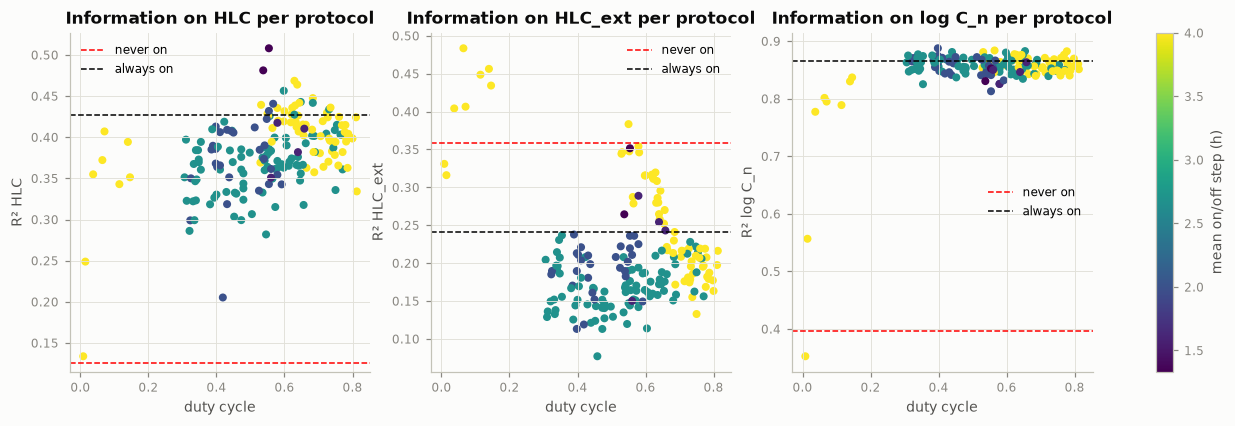

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
prbs_info = info[info["regime"] == "PRBS"]
for ax, target in zip(axes, ["HLC", "HLC_ext", "log C_n"]):
    sc = ax.scatter(prbs_info["duty cycle"], prbs_info[target], c=prbs_info["mean step (h)"], cmap="viridis", s=18)
    for r in ["never on", "always on"]:
        if r in set(info["regime"]):
            v = info.loc[info["regime"] == r, target].iloc[0]
            ax.axhline(v, ls="--", lw=1, color="k" if r == "always on" else "r", label=r)
    ax.set(xlabel="duty cycle", ylabel=f"R² {target}", title=f"Information on {target} per protocol")
    ax.legend(fontsize=8)
fig.colorbar(sc, ax=axes, label="mean on/off step (h)")
display(info.sort_values("HLC", ascending=False)[["size", "regime", "duty cycle", "mean step (h)", *names]].head(5).round(3).rename_axis("best protocols for HLC"))
display(info.sort_values("HLC")[["size", "regime", "duty cycle", "mean step (h)", *names]].head(5).round(3).rename_axis("worst protocols for HLC"))

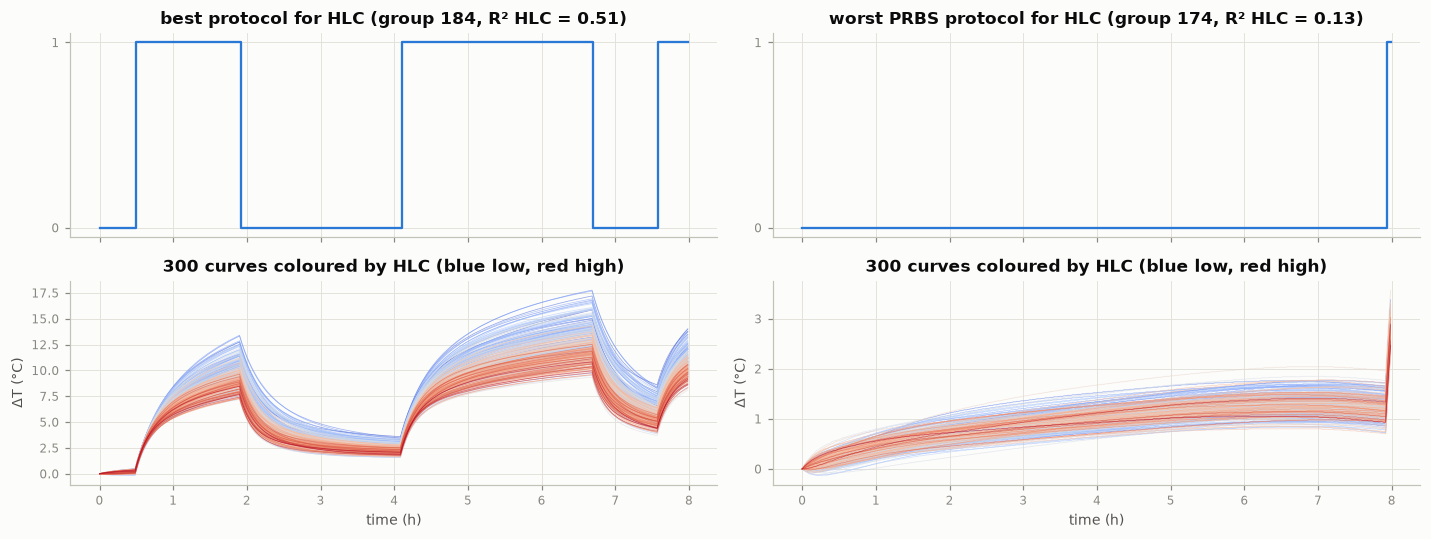

In [8]:
best, worst = info["HLC"].idxmax(), info.loc[info["regime"] == "PRBS", "HLC"].idxmin()
fig, axes = plt.subplots(2, 2, figsize=(13, 5), sharex=True)
for col, (g, title) in enumerate([(best, "best protocol for HLC"), (worst, "worst PRBS protocol for HLC")]):
    idx = (group == int(g)).nonzero().flatten()[:300]
    hlc = tensors.targets[idx, 0].numpy()
    axes[0, col].step(hours, u_rep[int(g)].numpy(), where="post")
    axes[0, col].set(title=f"{title} (group {g}, R² HLC = {info.loc[g, 'HLC']:.2f})", yticks=[0, 1])
    order = np.argsort(hlc)
    colours = plt.cm.coolwarm((hlc[order] - hlc.min()) / np.ptp(hlc))
    for k, c in zip(order, colours):
        axes[1, col].plot(hours, dT[idx[k]].numpy(), color=c, lw=0.5, alpha=0.6)
    axes[1, col].set(xlabel="time (h)", ylabel="ΔT (°C)", title="300 curves coloured by HLC (blue low, red high)")
fig.tight_layout()

## 5. Would a longer test help? Information vs observation time

Same ridge regression, using only the first `T` hours of the curve, for the unheated group, the
always-on group and the best PRBS protocol for HLC.

never on                           always on                           best PRBS (group 184)                          
           HLC HLC_ext log tau_n log C_n       HLC HLC_ext log tau_n log C_n                   HLC HLC_ext log tau_n log C_n
hours                                                                                                                       
0.5      0.014   0.000     0.017   0.067     0.239   0.056     0.122   0.734                 0.013   0.001     0.009   0.060
1.0      0.039  -0.000     0.059   0.216     0.253   0.058     0.134   0.789                 0.275   0.080     0.111   0.748
2.0      0.052  -0.000     0.091   0.318     0.284   0.071     0.137   0.838                 0.304   0.077     0.123   0.832
3.0      0.071   0.094     0.118   0.324     0.301   0.078     0.135   0.850                 0.303   0.057     0.125   0.857
4.0      0.080   0.166     0.149   0.339     0.312   0.080     0.136   0.852                 0.296   0.057     0.123   0.861
6.0      0.121   0.338     0.178   0.347     0.350   0.125     0.161   0.852                 0.319   0.095     0.136   0.861
8.0      0.134   0.370     0.221   0.440     0.417   0.272     0.236   0.860                 0.429   0.324     0.232   0.864

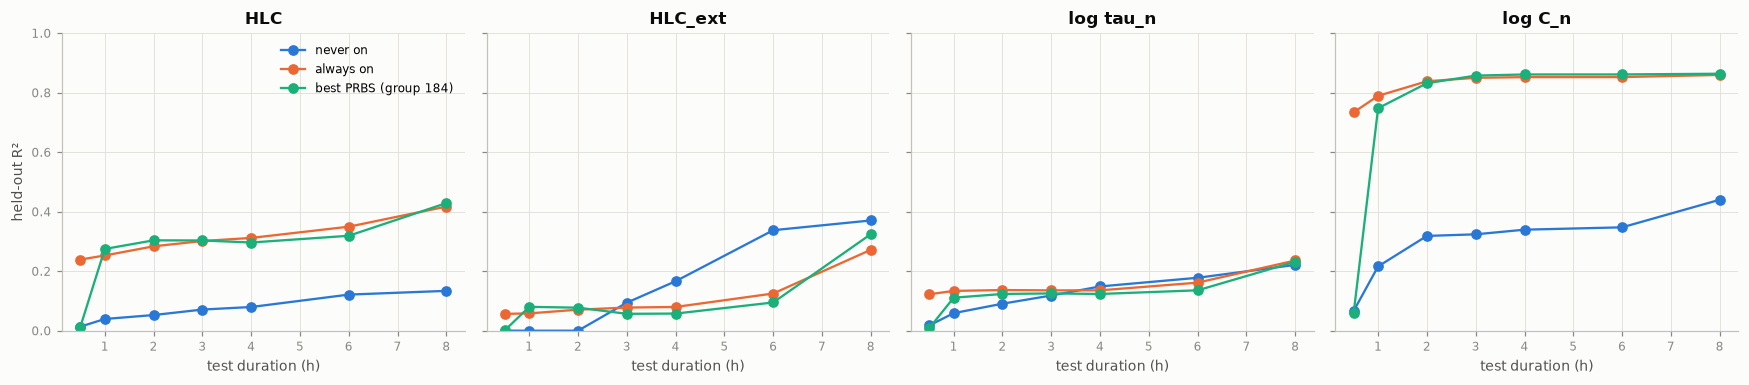

In [9]:
durations = [0.5, 1, 2, 3, 4, 6, 8]
picks = {"never on": never, "always on": always, f"best PRBS (group {best})": int(best)}
watch = ["HLC", "HLC_ext", "log tau_n", "log C_n"]
fig, axes = plt.subplots(1, len(watch), figsize=(16, 3.6), sharey=True)
table = {}
for label, g in picks.items():
    idx = (group == g).nonzero().flatten()
    idx = idx[torch.randperm(len(idx))[:20_000]]
    r2 = np.stack([I.ridge_r2(dT[idx][:, : int(t * 60) : STEP], Y[idx]).numpy() for t in durations])
    table[label] = pd.DataFrame(r2, index=durations, columns=names)
    for ax, target in zip(axes, watch):
        ax.plot(durations, r2[:, names.index(target)], marker="o", label=label)
for ax, target in zip(axes, watch):
    ax.set(xlabel="test duration (h)", title=target, ylim=(0, 1))
axes[0].set_ylabel("held-out R²")
axes[0].legend(fontsize=8)
fig.tight_layout()
display(pd.concat(table, axis=1)[[(k, t) for k in table for t in watch]].round(3).rename_axis("hours"))

## 6. Curve twins: same input, (almost) the same curve, different buildings

For random simulations of a group, the closest other curve of the same group is its "twin".
If the curve determined a target, twins would have close values of that target. The ratio of
the median target difference between twins to that between random pairs measures it directly:
**0 = fully determined by the curve, 1 = the curve says nothing**.

In [10]:
twin_rows, examples = {}, {}
for label, g in {"always on": always, f"PRBS (group {first_prbs})": first_prbs, f"best PRBS (group {best})": int(best)}.items():
    idx = (group == g).nonzero().flatten()
    c = dT[idx][:, ::STEP]
    q, t = I.curve_twins(c, n_query=3000)
    rnd = torch.randint(len(idx), (len(q),))
    d_twin = (Y[idx[q]] - Y[idx[t]]).abs().median(0).values
    d_rand = (Y[idx[q]] - Y[idx[rnd]]).abs().median(0).values
    twin_rows[label] = pd.Series((d_twin / d_rand).numpy(), index=names)
    gap = (c[q] - c[t]).abs().max(1).values
    examples[label] = (idx, q, t, gap)
display(pd.DataFrame(twin_rows).T.round(2).rename_axis("median |Δ| twins / random pairs"))

,HLC,HLC_mit,HLC_ext,log tau_b,log tau_n,log tau_inf,log C_n
median |Δ| twins / random pairs,,,,,,,
always on,0.75,0.83,0.90,1.00,0.91,1.02,0.38
PRBS (group 1),0.76,0.83,0.92,0.99,0.95,1.00,0.39
best PRBS (group 184),0.73,0.80,0.94,0.93,0.94,0.97,0.39


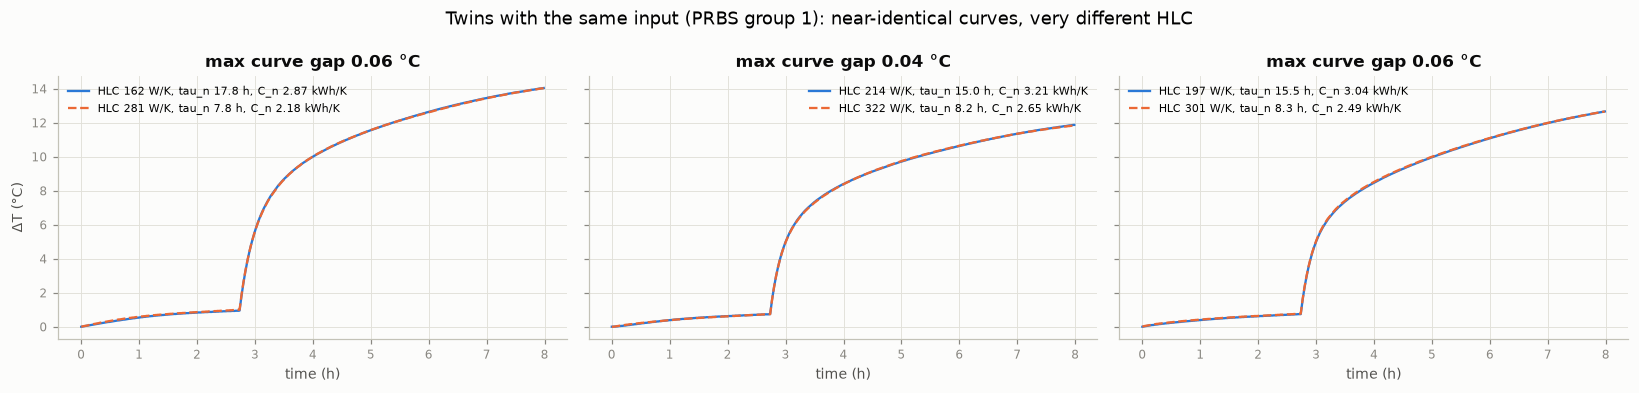

In [11]:
idx, q, t, gap = examples[f"PRBS (group {first_prbs})"]
close = gap < gap.quantile(0.25)  # twins within the closest quarter of curve gaps
diff = (tensors.targets[idx[q], 0] - tensors.targets[idx[t], 0]).abs()
pick = (diff * close).argsort(descending=True)[:3]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, k in zip(axes, pick):
    for j, ls in [(q[k], "-"), (t[k], "--")]:
        y6 = tensors.targets[idx[j]]
        ax.plot(hours, dT[idx[j]].numpy(), ls=ls, label=f"HLC {y6[0]:.0f} W/K, tau_n {y6[4]:.1f} h, C_n {y6[0] * y6[4] / 1000:.2f} kWh/K")
    ax.set(xlabel="time (h)", title=f"max curve gap {gap[k]:.2f} °C")
    ax.legend(fontsize=7)
axes[0].set_ylabel("ΔT (°C)")
fig.suptitle(f"Twins with the same input (PRBS group {first_prbs}): near-identical curves, very different HLC")
fig.tight_layout()

## 7. What does the curve measure? Correlation with the targets over time

Correlation between the temperature rise at time `t` and each target, within an input group.

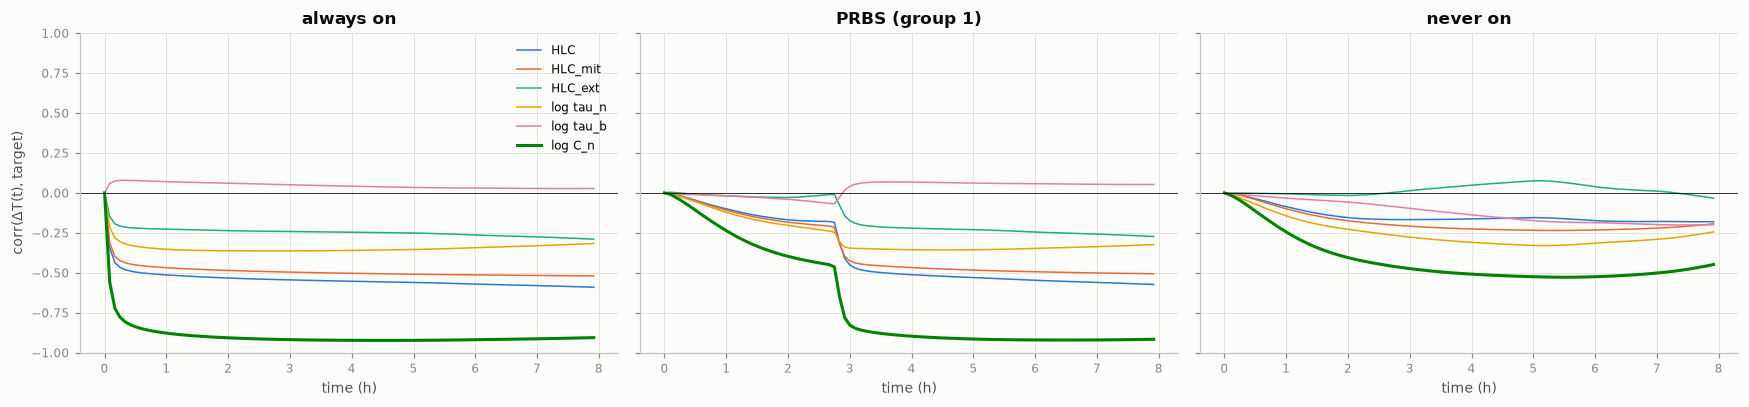

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, (label, g) in zip(axes, {"always on": always, f"PRBS (group {first_prbs})": first_prbs, "never on": never}.items()):
    idx = (group == g).nonzero().flatten()
    idx = idx[torch.randperm(len(idx))[:20_000]]
    corr = I.correlation_over_time(dT[idx][:, ::STEP], Y[idx]).numpy()
    for target in ["HLC", "HLC_mit", "HLC_ext", "log tau_n", "log tau_b", "log C_n"]:
        ax.plot(hours[::STEP], corr[:, names.index(target)], label=target, lw=2 if target == "log C_n" else 1)
    ax.axhline(0, color="k", lw=0.5)
    ax.set(xlabel="time (h)", title=label, ylim=(-1, 1))
axes[0].set_ylabel("corr(ΔT(t), target)")
axes[0].legend(fontsize=8)
fig.tight_layout()

## 8. Synthesis: what the data says about each problem

**1. The dataset is a set of repeated protocols, not 1M different tests.** Only **2,798 distinct
heating sequences** (one PRBS seed for all simulations); 65 % of the simulations share their exact
input with at least 1,000 others; the most frequent PRBS sequences are single steps (one switch).
**99.99 % of validation inputs also appear in training**, so all scores so far are scores on
*known protocols*: generalisation to a new heating sequence is not measured by the current split.

**2. Without heating, the hidden initial state dominates; with heating, the building does.**
Within an identical-input group, the building (targets known exactly) explains only **20 %** of
the variance of unheated curves, but **94 %** of always-on curves (87 % after 1 h) and up to
**98 %** at the end of PRBS curves. So the hidden initial state is the main nuisance only for
unheated tests (8.4 % of the data). It does not explain the plateau of heated tests.

**3. The real cause of the plateau: different buildings produce the same curve.** Under heating
the curve is almost a deterministic function of the building, yet the targets cannot be read back
from it: the mapping from the 5 building quantities to the curve is many-to-one.
"Curve twins" (same input, closest curve) differ in their targets almost as much as random pairs:
median gap ratio **0.73–0.76 for HLC, 0.80–0.83 for HLC_mit, 0.90–0.94 for HLC_ext and tau_n,
0.93–1.02 for tau_b and tau_inf** (1 = the curve says nothing), but only **0.38–0.39 for the
effective capacity `C_n = HLC x tau_n`**. This is why models memorise real labels barely faster
than shuffled ones: for most targets the curve does not carry the label.

**4. Information profile per target (189 protocols with ≥ 1,000 simulations, linear lower bound).**

| Target | median R² (heated protocols) | best protocol | unheated |
|---|---|---|---|
| log C_n | 0.86 | 0.89 | 0.40 |
| HLC | 0.38 | 0.51 | 0.13 |
| HLC_mit | 0.26 | 0.35 | 0.08 |
| HLC_ext | 0.19 | 0.48 | 0.36 |
| log tau_n | 0.19 | 0.29 | 0.21 |
| log tau_b, log tau_inf | 0.03–0.04 | 0.25 / 0.18 | 0.14 / 0.11 |

The trained TCN (notebook 04: HLC R² 0.42, C_n 0.84, tau_b 0.10, tau_inf 0.08) sits at these
bounds: the models are close to the information limit, which is why no architecture changes it.
Unheated tests carry more information on `HLC_ext` and `tau_b` than heated ones (the free response
probes the envelope), and almost none on HLC.

**5. Longer tests would help HLC and the time constants, not C_n.** `C_n` saturates within 2–3 h
(R² 0.73 after 30 min, 0.85 at 3 h with the heater on). HLC, HLC_ext and tau_n are still rising at
8 h (always on: HLC 0.31 at 4 h → 0.42 at 8 h; HLC_ext 0.08 → 0.27): the late part of the test,
where the slow heat exchanges show up, carries the information that 8 h only starts to reveal.

**6. Which tests are informative.** Heating is required for HLC (unheated: R² 0.13). The best
protocols for HLC have a duty cycle of about 0.55–0.65 with long steps (1.3–4 h); near-zero duty
cycles are as poor as no heating.

**7. Measurement resolution.** Without heating, 72 % of 1-min increments are exactly zero and
99 % are within one 0.01 °C quantum: slopes must be estimated over tens of minutes. Not a cause of
the plateau, but a reason to avoid fine derivative features.

**What follows for the modelling and the report.**

* The plateau is an **identifiability limit of 8 h tests** (many-to-one mapping), not a model or
  optimisation problem. Report `C_n` (well measured) with calibrated intervals for the six
  indicators, rather than chasing architectures.
* **Evaluate generalisation to new protocols**: hold out whole heating sequences (group split by
  input) to check that the model has not just memorised the 2,798 protocols.
* For coEnergy's protocol design: heat, with steps of one hour or more, a duty cycle around 0.6, and
  test longer than 8 h when HLC and the time constants matter more than the effective capacity.